# 4. Aggregate Citi Bike trips by station and day

**Who worked on this:** Rune Lemmens

This notebook aggregates the cleaned trip CSV to one row per start station per day, then runs the aggregation-check visualizations. Run 03_cleaning.ipynb first.

In [2]:
from pathlib import Path

import pandas as pd

# Standalone paths and chunk size for Sections 6–6.2.
DATA_DIR = Path.cwd() / "data"
CLEANED_OUTPUT_PATH = DATA_DIR / "processed" / "citibike_trips_cleaned_2013_2019.csv"
AGGREGATED_OUTPUT_PATH = DATA_DIR / "processed" / "citibike_station_day_summary_2013_2019.csv"
CHUNK_SIZE = 200_000
if not CLEANED_OUTPUT_PATH.exists():
    raise FileNotFoundError(f"Cleaned trip CSV not found: {CLEANED_OUTPUT_PATH}. Run 03_cleaning.ipynb first.")

## 6. Aggregate cleaned trips by start station and day

Create one row per **start station per calendar day** in a plain CSV. Each row includes trip count, mean/min/max duration, member/casual counts, weekday (derived from the date), and available demographic summaries. The mean daily duration is the prediction target for a station-day model; for individual-trip duration prediction, use the cleaned trip-level file instead.

In [3]:
import sqlite3

AGGREGATED_OUTPUT_PATH = DATA_DIR / "processed" / "citibike_station_day_summary_2013_2019.csv"
AGGREGATION_DB_PATH = DATA_DIR / "processed" / "citibike_station_day_2013_2019.tmp.sqlite"
AGGREGATION_TEMP_PATH = AGGREGATED_OUTPUT_PATH.with_suffix(AGGREGATED_OUTPUT_PATH.suffix + ".tmp")
AGGREGATION_KEYS = ["trip_date", "start_station_id"]
AGGREGATED_COLUMNS = [
    *AGGREGATION_KEYS,
    "start_station_name", "start_lat", "start_lng", "day_of_week",
    "trip_count", "mean_trip_duration_s", "min_trip_duration_s", "max_trip_duration_s",
    "member_trip_count", "casual_trip_count",
    "birth_year_known_count", "mean_birth_year",
    "gender_0_trip_count", "gender_1_trip_count", "gender_2_trip_count",
]
AGGREGATED_OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
if not CLEANED_OUTPUT_PATH.exists():
    raise FileNotFoundError("Run Section 5 cleaning first; cleaned 2013–2019 trip file is missing.")

AGGREGATION_TEMP_PATH.unlink(missing_ok=True)
AGGREGATION_DB_PATH.unlink(missing_ok=True)
connection = sqlite3.connect(AGGREGATION_DB_PATH)
connection.execute("PRAGMA journal_mode = OFF")
connection.execute("PRAGMA synchronous = OFF")
connection.execute("PRAGMA temp_store = FILE")
connection.execute("""
    CREATE TABLE station_day (
        trip_date TEXT NOT NULL,
        start_station_id TEXT NOT NULL,
        start_station_name TEXT,
        start_lat REAL,
        start_lng REAL,
        day_of_week INTEGER NOT NULL,
        trip_count INTEGER NOT NULL,
        duration_sum REAL NOT NULL,
        min_duration REAL NOT NULL,
        max_duration REAL NOT NULL,
        member_trip_count INTEGER NOT NULL,
        casual_trip_count INTEGER NOT NULL,
        birth_year_sum REAL NOT NULL,
        birth_year_count INTEGER NOT NULL,
        gender_0 INTEGER NOT NULL,
        gender_1 INTEGER NOT NULL,
        gender_2 INTEGER NOT NULL,
        PRIMARY KEY (trip_date, start_station_id)
    ) WITHOUT ROWID
""")

upsert_sql = """
    INSERT INTO station_day VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
    ON CONFLICT (trip_date, start_station_id)
    DO UPDATE SET
        start_station_name = COALESCE(station_day.start_station_name, excluded.start_station_name),
        start_lat = COALESCE(station_day.start_lat, excluded.start_lat),
        start_lng = COALESCE(station_day.start_lng, excluded.start_lng),
        trip_count = station_day.trip_count + excluded.trip_count,
        duration_sum = station_day.duration_sum + excluded.duration_sum,
        min_duration = MIN(station_day.min_duration, excluded.min_duration),
        max_duration = MAX(station_day.max_duration, excluded.max_duration),
        member_trip_count = station_day.member_trip_count + excluded.member_trip_count,
        casual_trip_count = station_day.casual_trip_count + excluded.casual_trip_count,
        birth_year_sum = station_day.birth_year_sum + excluded.birth_year_sum,
        birth_year_count = station_day.birth_year_count + excluded.birth_year_count,
        gender_0 = station_day.gender_0 + excluded.gender_0,
        gender_1 = station_day.gender_1 + excluded.gender_1,
        gender_2 = station_day.gender_2 + excluded.gender_2
"""


def aggregate_clean_chunk(chunk: pd.DataFrame) -> pd.DataFrame:
    started = pd.to_datetime(chunk["started_at"], format="mixed", errors="coerce")
    chunk["trip_date"] = started.dt.strftime("%Y-%m-%d")
    chunk["day_of_week"] = started.dt.dayofweek
    chunk = chunk.loc[chunk["trip_date"].notna()].copy()
    chunk["start_station_id"] = chunk["start_station_id"].astype("string").fillna("unknown").str.strip().replace("", "unknown")
    for column in ("trip_duration_s", "birth_year", "gender", "start_lat", "start_lng"):
        chunk[column] = pd.to_numeric(chunk[column], errors="coerce")

    rider_type = chunk["member_casual"].astype("string").str.lower()
    chunk["member_trip_count"] = rider_type.eq("member").astype("int64")
    chunk["casual_trip_count"] = rider_type.eq("casual").astype("int64")
    chunk["birth_year_sum"] = chunk["birth_year"].fillna(0)
    chunk["birth_year_known"] = chunk["birth_year"].notna().astype("int64")
    gender = chunk["gender"]
    chunk["gender_0"] = gender.eq(0).astype("int64")
    chunk["gender_1"] = gender.eq(1).astype("int64")
    chunk["gender_2"] = gender.eq(2).astype("int64")

    return chunk.groupby(AGGREGATION_KEYS, dropna=False, observed=True, sort=False).agg(
        start_station_name=("start_station_name", "first"),
        start_lat=("start_lat", "first"),
        start_lng=("start_lng", "first"),
        day_of_week=("day_of_week", "first"),
        trip_count=("trip_duration_s", "size"),
        duration_sum=("trip_duration_s", "sum"),
        min_duration=("trip_duration_s", "min"),
        max_duration=("trip_duration_s", "max"),
        member_trip_count=("member_trip_count", "sum"),
        casual_trip_count=("casual_trip_count", "sum"),
        birth_year_sum=("birth_year_sum", "sum"),
        birth_year_count=("birth_year_known", "sum"),
        gender_0=("gender_0", "sum"),
        gender_1=("gender_1", "sum"),
        gender_2=("gender_2", "sum"),
    ).reset_index()

input_trip_count = 0
invalid_aggregation_date_count = 0
aggregate_group_count = 0
try:
    with pd.read_csv(CLEANED_OUTPUT_PATH, chunksize=CHUNK_SIZE, low_memory=False) as cleaned_reader:
        for aggregate_chunk in cleaned_reader:
            input_trip_count += len(aggregate_chunk)
            parsed_dates = pd.to_datetime(aggregate_chunk["started_at"], format="mixed", errors="coerce")
            invalid_aggregation_date_count += int(parsed_dates.isna().sum())
            grouped_chunk = aggregate_clean_chunk(aggregate_chunk)
            if not grouped_chunk.empty:
                connection.executemany(upsert_sql, grouped_chunk.itertuples(index=False, name=None))
                connection.commit()

    group_count = connection.execute("SELECT COUNT(*) FROM station_day").fetchone()[0]
    query = """
        SELECT trip_date, start_station_id, start_station_name, start_lat, start_lng, day_of_week,
               trip_count, duration_sum / NULLIF(trip_count, 0), min_duration, max_duration,
               member_trip_count, casual_trip_count,
               birth_year_count, birth_year_sum / NULLIF(birth_year_count, 0),
               gender_0, gender_1, gender_2
        FROM station_day
        ORDER BY trip_date, start_station_id
    """
    with open(AGGREGATION_TEMP_PATH, "w", encoding="utf-8", newline="") as output_file:
        output_file.write(",".join(AGGREGATED_COLUMNS) + "\n")
        cursor = connection.execute(query)
        while records := cursor.fetchmany(50_000):
            summary_chunk = pd.DataFrame.from_records(records, columns=AGGREGATED_COLUMNS)
            summary_chunk.to_csv(output_file, index=False, header=False)
            aggregate_group_count += len(summary_chunk)

    if aggregate_group_count != group_count:
        raise RuntimeError(f"Expected {group_count:,} groups, wrote {aggregate_group_count:,}.")
    AGGREGATION_TEMP_PATH.replace(AGGREGATED_OUTPUT_PATH)
finally:
    connection.close()
    AGGREGATION_DB_PATH.unlink(missing_ok=True)
    AGGREGATION_TEMP_PATH.unlink(missing_ok=True)

aggregated_size_gb = AGGREGATED_OUTPUT_PATH.stat().st_size / 1_000_000_000
print(f"Trips aggregated: {input_trip_count:,}")
print(f"Rows with invalid start dates skipped: {invalid_aggregation_date_count:,}")
print(f"Station-day groups: {aggregate_group_count:,}")
print(f"Aggregated output: {AGGREGATED_OUTPUT_PATH} ({aggregated_size_gb:.2f} GB)")

Trips aggregated: 91,854,873
Rows with invalid start dates skipped: 0
Station-day groups: 1,297,662
Aggregated output: c:\Users\lemme\OneDrive\Desktop\2025_School\deep learning\Ctrl-Alt-Defeat\NYC Citi Bike System Data\data\processed\citibike_station_day_summary_2013_2019.csv (0.17 GB)


## 6.2 Visualize some basic information to ensure aggregation happened properly

These plots use the station-day summary produced in Section 6. They show (1) average rides per station-day for each weekday, (2) trip-weighted mean duration by weekday, and (3) stations with the highest average rides per active station-day. The file is read in chunks to keep memory use low.

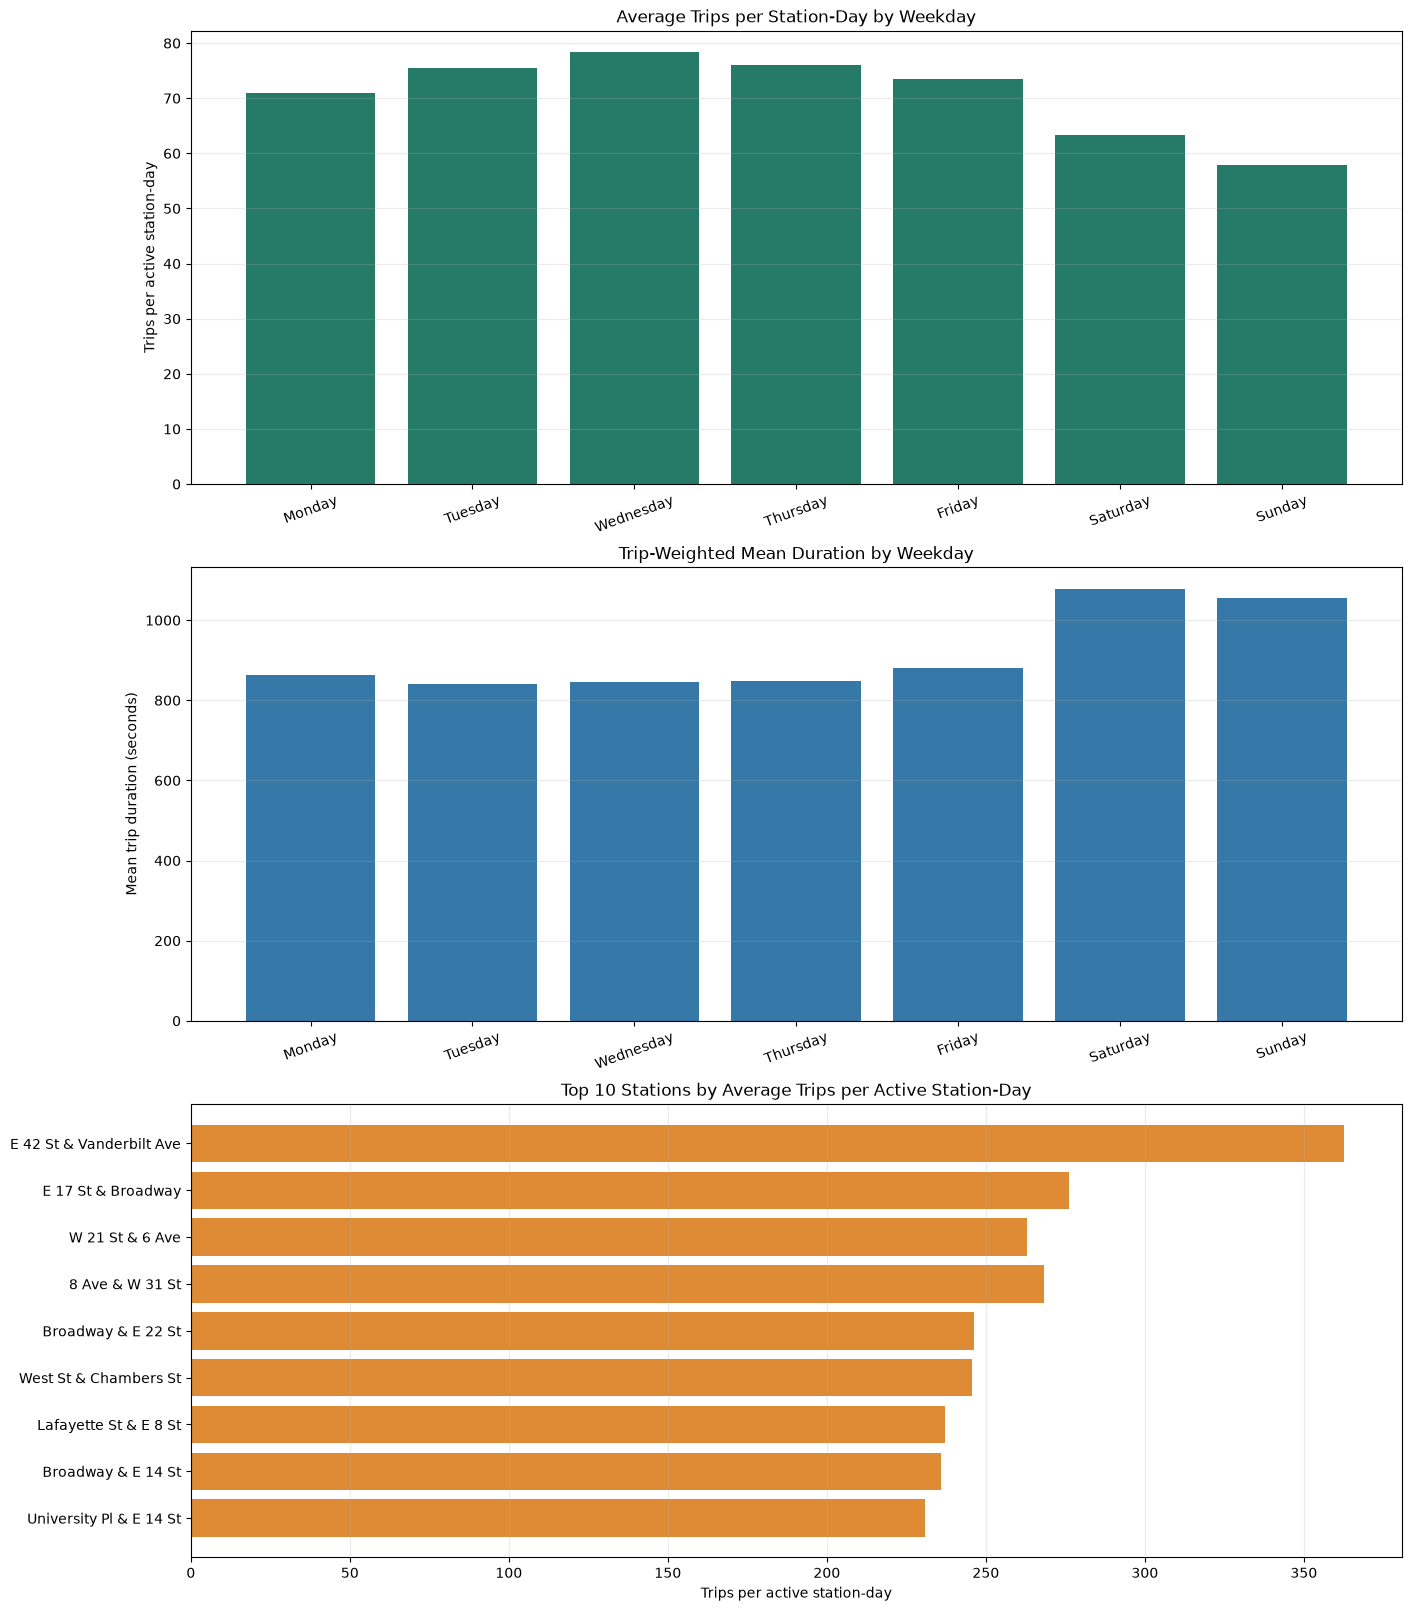

In [4]:
import matplotlib.pyplot as plt

if not AGGREGATED_OUTPUT_PATH.exists():
    raise FileNotFoundError("Run Section 6 aggregation before plotting.")

plot_columns = [
    "start_station_id", "start_station_name", "day_of_week", "trip_count",
    "mean_trip_duration_s",
]
weekday_trip_totals = [0] * 7
weekday_station_day_counts = [0] * 7
weekday_duration_totals = [0.0] * 7
station_totals = {}

for plot_chunk in pd.read_csv(
    AGGREGATED_OUTPUT_PATH,
    usecols=plot_columns,
    chunksize=CHUNK_SIZE,
    low_memory=False,
):
    plot_chunk["day_of_week"] = pd.to_numeric(plot_chunk["day_of_week"], errors="coerce")
    plot_chunk["trip_count"] = pd.to_numeric(plot_chunk["trip_count"], errors="coerce")
    plot_chunk["mean_trip_duration_s"] = pd.to_numeric(
        plot_chunk["mean_trip_duration_s"], errors="coerce"
    )
    plot_chunk = plot_chunk.dropna(subset=["day_of_week", "trip_count"])
    plot_chunk["day_of_week"] = plot_chunk["day_of_week"].astype("int8")

    for day in range(7):
        day_rows = plot_chunk.loc[plot_chunk["day_of_week"] == day]
        weekday_trip_totals[day] += int(day_rows["trip_count"].sum())
        weekday_station_day_counts[day] += len(day_rows)
        valid_duration = day_rows["mean_trip_duration_s"].notna()
        weekday_duration_totals[day] += float(
            (
                day_rows.loc[valid_duration, "mean_trip_duration_s"]
                * day_rows.loc[valid_duration, "trip_count"]
            ).sum()
        )

    station_chunk = plot_chunk.groupby(
        ["start_station_id", "start_station_name"], observed=True, dropna=False
    ).agg(
        trip_total=("trip_count", "sum"),
        active_station_days=("trip_count", "size"),
    )
    for (station_id, station_name), row in station_chunk.iterrows():
        station = station_totals.setdefault(station_id, {
            "name": station_name,
            "trip_total": 0,
            "active_station_days": 0,
        })
        station["trip_total"] += int(row["trip_total"])
        station["active_station_days"] += int(row["active_station_days"])

weekday_names = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
average_trips_per_station_day = [
    total / count if count else float("nan")
    for total, count in zip(weekday_trip_totals, weekday_station_day_counts)
]
weighted_mean_duration = [
    total / trip_count if trip_count else float("nan")
    for total, trip_count in zip(weekday_duration_totals, weekday_trip_totals)
]

top_stations = sorted(
    station_totals.items(),
    key=lambda item: item[1]["trip_total"] / item[1]["active_station_days"]
    if item[1]["active_station_days"] else 0,
)[-10:]
top_station_labels = [
    str(details["name"]) if pd.notna(details["name"]) else str(station_id)
    for station_id, details in top_stations
]
top_station_averages = [
    details["trip_total"] / details["active_station_days"]
    for _, details in top_stations
]

fig, axes = plt.subplots(3, 1, figsize=(14, 16), constrained_layout=True)
axes[0].bar(weekday_names, average_trips_per_station_day, color="#267a68")
axes[0].set_title("Average Trips per Station-Day by Weekday")
axes[0].set_ylabel("Trips per active station-day")
axes[0].tick_params(axis="x", rotation=20)
axes[0].grid(axis="y", alpha=0.25)

axes[1].bar(weekday_names, weighted_mean_duration, color="#3678a8")
axes[1].set_title("Trip-Weighted Mean Duration by Weekday")
axes[1].set_ylabel("Mean trip duration (seconds)")
axes[1].tick_params(axis="x", rotation=20)
axes[1].grid(axis="y", alpha=0.25)

axes[2].barh(top_station_labels, top_station_averages, color="#df8b35")
axes[2].set_title("Top 10 Stations by Average Trips per Active Station-Day")
axes[2].set_xlabel("Trips per active station-day")
axes[2].grid(axis="x", alpha=0.25)

plt.show()